In [1]:
import os
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
PROCESSED_PATH = "../data/processed"

full_data = pd.read_parquet(
    os.path.join(PROCESSED_PATH, "pamap2_full.parquet")
)

limited_data = pd.read_parquet(
    os.path.join(PROCESSED_PATH, "pamap2_limited.parquet")
)

print("Full dataset shape:", full_data.shape)
print("Limited dataset shape:", limited_data.shape)

Full dataset shape: (1921389, 55)
Limited dataset shape: (1931706, 21)


In [3]:
# Full feature set
full_X = full_data.drop(
    columns=["activity_id", "subject_id", "timestamp"]
)
full_y = full_data["activity_id"]

# Limited feature set
limited_X = limited_data.drop(
    columns=["activity_id", "subject_id", "timestamp"]
)
limited_y = limited_data["activity_id"]

print("Full X shape:", full_X.shape)
print("Full y shape:", full_y.shape)

print("Limited X shape:", limited_X.shape)
print("Limited y shape:", limited_y.shape)

Full X shape: (1921389, 52)
Full y shape: (1921389,)
Limited X shape: (1931706, 18)
Limited y shape: (1931706,)


In [4]:
# 85% training, 15% testing
full_X_train, full_X_test, full_y_train, full_y_test = train_test_split(
    full_X,
    full_y,
    test_size=0.15,
    random_state=42,
    stratify=full_y
)

limited_X_train, limited_X_test, limited_y_train, limited_y_test = train_test_split(
    limited_X,
    limited_y,
    test_size=0.15,
    random_state=42,
    stratify=limited_y
)

print("FULL DATASET")
print("Training:", full_X_train.shape)
print("Testing :", full_X_test.shape)

print("\nLIMITED DATASET")
print("Training:", limited_X_train.shape)
print("Testing :", limited_X_test.shape)

FULL DATASET
Training: (1633180, 52)
Testing : (288209, 52)

LIMITED DATASET
Training: (1641950, 18)
Testing : (289756, 18)


In [5]:
# Create scalers
full_scaler = StandardScaler()
limited_scaler = StandardScaler()

# Fit ONLY on training data
full_X_train_scaled = full_scaler.fit_transform(full_X_train)
limited_X_train_scaled = limited_scaler.fit_transform(limited_X_train)

# Transform test data using the training-fitted scalers
full_X_test_scaled = full_scaler.transform(full_X_test)
limited_X_test_scaled = limited_scaler.transform(limited_X_test)

print("Scaling completed successfully.")

print("\nFull scaled training shape:", full_X_train_scaled.shape)
print("Full scaled testing shape :", full_X_test_scaled.shape)

print("\nLimited scaled training shape:", limited_X_train_scaled.shape)
print("Limited scaled testing shape :", limited_X_test_scaled.shape)

Scaling completed successfully.

Full scaled training shape: (1633180, 52)
Full scaled testing shape : (288209, 52)

Limited scaled training shape: (1641950, 18)
Limited scaled testing shape : (289756, 18)


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report

print("Logistic Regression tools imported.")

Logistic Regression tools imported.


In [7]:
# Logistic Regression - Full Feature Set

logreg_full = LogisticRegression(
    C=0.01,
    penalty="l2",
    solver="sag",
    max_iter=100,
    random_state=42
)

print("Training Logistic Regression on full dataset...")

logreg_full.fit(
    full_X_train_scaled,
    full_y_train
)

print("Full-dataset Logistic Regression training completed.")

Training Logistic Regression on full dataset...


c:\Human-Activity-Classification\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Full-dataset Logistic Regression training completed.


In [8]:
# Logistic Regression - Limited Feature Set

logreg_limited = LogisticRegression(
    C=0.01,
    solver="sag",
    max_iter=100,
    random_state=42
)

print("Training Logistic Regression on limited dataset...")

logreg_limited.fit(
    limited_X_train_scaled,
    limited_y_train
)

print("Limited-dataset Logistic Regression training completed.")

Training Logistic Regression on limited dataset...
Limited-dataset Logistic Regression training completed.


In [9]:
# Evaluate Logistic Regression models

print("Evaluating Full Feature Set...")

full_y_pred_logreg = logreg_full.predict(full_X_test_scaled)
full_logreg_accuracy = accuracy_score(
    full_y_test,
    full_y_pred_logreg
)

print(
    f"Full Feature Set Accuracy: "
    f"{full_logreg_accuracy:.4f} "
    f"({full_logreg_accuracy * 100:.2f}%)"
)


print("\nEvaluating Limited Feature Set...")

limited_y_pred_logreg = logreg_limited.predict(limited_X_test_scaled)
limited_logreg_accuracy = accuracy_score(
    limited_y_test,
    limited_y_pred_logreg
)

print(
    f"Limited Feature Set Accuracy: "
    f"{limited_logreg_accuracy:.4f} "
    f"({limited_logreg_accuracy * 100:.2f}%)"
)

Evaluating Full Feature Set...
Full Feature Set Accuracy: 0.8570 (85.70%)

Evaluating Limited Feature Set...
Limited Feature Set Accuracy: 0.6672 (66.72%)


In [10]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split

print("SVM tools imported.")

SVM tools imported.


In [11]:
# Create manageable stratified samples for RBF SVM

SVM_TRAIN_SIZE = 10000
SVM_TEST_SIZE = 20000

# Full feature set
svm_full_X_train, _, svm_full_y_train, _ = train_test_split(
    full_X_train_scaled,
    full_y_train,
    train_size=SVM_TRAIN_SIZE,
    random_state=42,
    stratify=full_y_train
)

# Limited feature set
svm_limited_X_train, _, svm_limited_y_train, _ = train_test_split(
    limited_X_train_scaled,
    limited_y_train,
    train_size=SVM_TRAIN_SIZE,
    random_state=42,
    stratify=limited_y_train
)

# Test samples for practical evaluation
_, svm_full_X_test, _, svm_full_y_test = train_test_split(
    full_X_test_scaled,
    full_y_test,
    test_size=SVM_TEST_SIZE,
    random_state=42,
    stratify=full_y_test
)

_, svm_limited_X_test, _, svm_limited_y_test = train_test_split(
    limited_X_test_scaled,
    limited_y_test,
    test_size=SVM_TEST_SIZE,
    random_state=42,
    stratify=limited_y_test
)

print("SVM samples created successfully.")

print("\nFull SVM training:", svm_full_X_train.shape)
print("Full SVM testing :", svm_full_X_test.shape)

print("\nLimited SVM training:", svm_limited_X_train.shape)
print("Limited SVM testing :", svm_limited_X_test.shape)

SVM samples created successfully.

Full SVM training: (10000, 52)
Full SVM testing : (20000, 52)

Limited SVM training: (10000, 18)
Limited SVM testing : (20000, 18)


In [12]:
# RBF SVM - Full Feature Set

svm_full = SVC(
    C=100,
    kernel="rbf",
    random_state=42
)

print("Training RBF SVM on full feature set...")

svm_full.fit(
    svm_full_X_train,
    svm_full_y_train
)

print("Full-feature RBF SVM training completed.")

Training RBF SVM on full feature set...
Full-feature RBF SVM training completed.


In [13]:
# RBF SVM - Limited Feature Set

svm_limited = SVC(
    C=1000,
    kernel="rbf",
    random_state=42
)

print("Training RBF SVM on limited feature set...")

svm_limited.fit(
    svm_limited_X_train,
    svm_limited_y_train
)

print("Limited-feature RBF SVM training completed.")

Training RBF SVM on limited feature set...
Limited-feature RBF SVM training completed.


In [14]:
# Evaluate SVM models

print("Evaluating Full Feature Set...")

svm_full_y_pred = svm_full.predict(svm_full_X_test)

svm_full_accuracy = accuracy_score(
    svm_full_y_test,
    svm_full_y_pred
)

print(
    f"Full Feature Set SVM Accuracy: "
    f"{svm_full_accuracy:.4f} "
    f"({svm_full_accuracy * 100:.2f}%)"
)


print("\nEvaluating Limited Feature Set...")

svm_limited_y_pred = svm_limited.predict(svm_limited_X_test)

svm_limited_accuracy = accuracy_score(
    svm_limited_y_test,
    svm_limited_y_pred
)

print(
    f"Limited Feature Set SVM Accuracy: "
    f"{svm_limited_accuracy:.4f} "
    f"({svm_limited_accuracy * 100:.2f}%)"
)

Evaluating Full Feature Set...
Full Feature Set SVM Accuracy: 0.9644 (96.44%)

Evaluating Limited Feature Set...
Limited Feature Set SVM Accuracy: 0.8882 (88.82%)


In [15]:
from sklearn.tree import DecisionTreeClassifier

print("Decision Tree tools imported.")

Decision Tree tools imported.


In [16]:
# Decision Tree - Full Feature Set

decision_tree_full = DecisionTreeClassifier(
    max_depth=15,
    criterion="gini",
    random_state=42
)

print("Training Decision Tree on full dataset...")

decision_tree_full.fit(
    full_X_train,
    full_y_train
)

print("Full-feature Decision Tree training completed.")

Training Decision Tree on full dataset...
Full-feature Decision Tree training completed.


In [17]:
# Decision Tree - Limited Feature Set

decision_tree_limited = DecisionTreeClassifier(
    max_depth=15,
    criterion="gini",
    random_state=42
)

print("Training Decision Tree on limited dataset...")

decision_tree_limited.fit(
    limited_X_train,
    limited_y_train
)

print("Limited-feature Decision Tree training completed.")

Training Decision Tree on limited dataset...
Limited-feature Decision Tree training completed.


In [18]:
# Evaluate Decision Tree models

print("Evaluating Full Feature Set...")

full_y_pred_tree = decision_tree_full.predict(full_X_test)

full_tree_accuracy = accuracy_score(
    full_y_test,
    full_y_pred_tree
)

print(
    f"Full Feature Set Decision Tree Accuracy: "
    f"{full_tree_accuracy:.4f} "
    f"({full_tree_accuracy * 100:.2f}%)"
)


print("\nEvaluating Limited Feature Set...")

limited_y_pred_tree = decision_tree_limited.predict(limited_X_test)

limited_tree_accuracy = accuracy_score(
    limited_y_test,
    limited_y_pred_tree
)

print(
    f"Limited Feature Set Decision Tree Accuracy: "
    f"{limited_tree_accuracy:.4f} "
    f"({limited_tree_accuracy * 100:.2f}%)"
)

Evaluating Full Feature Set...
Full Feature Set Decision Tree Accuracy: 0.9831 (98.31%)

Evaluating Limited Feature Set...
Limited Feature Set Decision Tree Accuracy: 0.9761 (97.61%)


In [19]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

print("AdaBoost tools imported.")

AdaBoost tools imported.


In [20]:
# Create manageable stratified samples for AdaBoost

ADABOOST_TRAIN_SIZE = 50000

# Full feature set
ada_full_X_train, _, ada_full_y_train, _ = train_test_split(
    full_X_train,
    full_y_train,
    train_size=ADABOOST_TRAIN_SIZE,
    random_state=42,
    stratify=full_y_train
)

# Limited feature set
ada_limited_X_train, _, ada_limited_y_train, _ = train_test_split(
    limited_X_train,
    limited_y_train,
    train_size=ADABOOST_TRAIN_SIZE,
    random_state=42,
    stratify=limited_y_train
)

print("AdaBoost samples created successfully.")

print("\nFull AdaBoost training:", ada_full_X_train.shape)
print("Limited AdaBoost training:", ada_limited_X_train.shape)

AdaBoost samples created successfully.

Full AdaBoost training: (50000, 52)
Limited AdaBoost training: (50000, 18)


In [21]:
# AdaBoost - Full Feature Set

ada_full = AdaBoostClassifier(
    n_estimators=500,
    learning_rate=1.0,
    random_state=42
)

print("Training AdaBoost on full feature set...")

ada_full.fit(
    ada_full_X_train,
    ada_full_y_train
)

print("Full-feature AdaBoost training completed.")

Training AdaBoost on full feature set...
Full-feature AdaBoost training completed.


In [22]:
# AdaBoost - Limited Feature Set

ada_limited = AdaBoostClassifier(
    n_estimators=500,
    learning_rate=1.0,
    random_state=42
)

print("Training AdaBoost on limited feature set...")

ada_limited.fit(
    ada_limited_X_train,
    ada_limited_y_train
)

print("Limited-feature AdaBoost training completed.")

Training AdaBoost on limited feature set...
Limited-feature AdaBoost training completed.


In [23]:
# Evaluate AdaBoost models

print("Evaluating Full Feature Set...")

ada_full_y_pred = ada_full.predict(full_X_test)

ada_full_accuracy = accuracy_score(
    full_y_test,
    ada_full_y_pred
)

print(
    f"Full Feature Set AdaBoost Accuracy: "
    f"{ada_full_accuracy:.4f} "
    f"({ada_full_accuracy * 100:.2f}%)"
)


print("\nEvaluating Limited Feature Set...")

ada_limited_y_pred = ada_limited.predict(limited_X_test)

ada_limited_accuracy = accuracy_score(
    limited_y_test,
    ada_limited_y_pred
)

print(
    f"Limited Feature Set AdaBoost Accuracy: "
    f"{ada_limited_accuracy:.4f} "
    f"({ada_limited_accuracy * 100:.2f}%)"
)

Evaluating Full Feature Set...
Full Feature Set AdaBoost Accuracy: 0.5897 (58.97%)

Evaluating Limited Feature Set...
Limited Feature Set AdaBoost Accuracy: 0.4976 (49.76%)


In [25]:
# Smaller stratified sample for practical AdaBoost training

ADABOOST_TRAIN_SIZE = 10000

ada_full_X_train_small, _, ada_full_y_train_small, _ = train_test_split(
    full_X_train,
    full_y_train,
    train_size=ADABOOST_TRAIN_SIZE,
    random_state=42,
    stratify=full_y_train
)

ada_limited_X_train_small, _, ada_limited_y_train_small, _ = train_test_split(
    limited_X_train,
    limited_y_train,
    train_size=ADABOOST_TRAIN_SIZE,
    random_state=42,
    stratify=limited_y_train
)

print("Smaller AdaBoost samples created.")
print("Full:", ada_full_X_train_small.shape)
print("Limited:", ada_limited_X_train_small.shape)

Smaller AdaBoost samples created.
Full: (10000, 52)
Limited: (10000, 18)


In [26]:
 # Practical AdaBoost configuration

ada_full = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=1.0,
    random_state=42
)

print("Training practical AdaBoost on full feature set...")

ada_full.fit(
    ada_full_X_train_small,
    ada_full_y_train_small
)

print("Full-feature AdaBoost training completed.")

Training practical AdaBoost on full feature set...
Full-feature AdaBoost training completed.


In [27]:
# Practical AdaBoost - Limited Feature Set

ada_limited = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=1.0,
    random_state=42
)

print("Training practical AdaBoost on limited feature set...")

ada_limited.fit(
    ada_limited_X_train_small,
    ada_limited_y_train_small
)

print("Limited-feature AdaBoost training completed.")

Training practical AdaBoost on limited feature set...
Limited-feature AdaBoost training completed.


In [28]:
# Evaluate practical AdaBoost models

print("Evaluating Full Feature Set...")

ada_full_y_pred = ada_full.predict(full_X_test)

ada_full_accuracy = accuracy_score(
    full_y_test,
    ada_full_y_pred
)

print(
    f"Full Feature Set AdaBoost Accuracy: "
    f"{ada_full_accuracy:.4f} "
    f"({ada_full_accuracy * 100:.2f}%)"
)


print("\nEvaluating Limited Feature Set...")

ada_limited_y_pred = ada_limited.predict(limited_X_test)

ada_limited_accuracy = accuracy_score(
    limited_y_test,
    ada_limited_y_pred
)

print(
    f"Limited Feature Set AdaBoost Accuracy: "
    f"{ada_limited_accuracy:.4f} "
    f"({ada_limited_accuracy * 100:.2f}%)"
)

Evaluating Full Feature Set...
Full Feature Set AdaBoost Accuracy: 0.8840 (88.40%)

Evaluating Limited Feature Set...
Limited Feature Set AdaBoost Accuracy: 0.7502 (75.02%)


In [29]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest tools imported.")

Random Forest tools imported.


In [30]:
# Create manageable stratified samples for Random Forest

RF_TRAIN_SIZE = 50000

rf_full_X_train, _, rf_full_y_train, _ = train_test_split(
    full_X_train,
    full_y_train,
    train_size=RF_TRAIN_SIZE,
    random_state=42,
    stratify=full_y_train
)

rf_limited_X_train, _, rf_limited_y_train, _ = train_test_split(
    limited_X_train,
    limited_y_train,
    train_size=RF_TRAIN_SIZE,
    random_state=42,
    stratify=limited_y_train
)

print("Random Forest samples created.")

print("Full:", rf_full_X_train.shape)
print("Limited:", rf_limited_X_train.shape)

Random Forest samples created.
Full: (50000, 52)
Limited: (50000, 18)


In [31]:
# Random Forest - Full Feature Set

rf_full = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest on full feature set...")

rf_full.fit(
    rf_full_X_train,
    rf_full_y_train
)

print("Full-feature Random Forest training completed.")

Training Random Forest on full feature set...
Full-feature Random Forest training completed.


In [32]:
# Random Forest - Limited Feature Set

rf_limited = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest on limited feature set...")

rf_limited.fit(
    rf_limited_X_train,
    rf_limited_y_train
)

print("Limited-feature Random Forest training completed.")

Training Random Forest on limited feature set...
Limited-feature Random Forest training completed.


In [33]:
# Evaluate Random Forest models

print("Evaluating Full Feature Set...")

rf_full_y_pred = rf_full.predict(full_X_test)

rf_full_accuracy = accuracy_score(
    full_y_test,
    rf_full_y_pred
)

print(
    f"Full Feature Set Random Forest Accuracy: "
    f"{rf_full_accuracy:.4f} "
    f"({rf_full_accuracy * 100:.2f}%)"
)


print("\nEvaluating Limited Feature Set...")

rf_limited_y_pred = rf_limited.predict(limited_X_test)

rf_limited_accuracy = accuracy_score(
    limited_y_test,
    rf_limited_y_pred
)

print(
    f"Limited Feature Set Random Forest Accuracy: "
    f"{rf_limited_accuracy:.4f} "
    f"({rf_limited_accuracy * 100:.2f}%)"
)

Evaluating Full Feature Set...
Full Feature Set Random Forest Accuracy: 0.9922 (99.22%)

Evaluating Limited Feature Set...
Limited Feature Set Random Forest Accuracy: 0.9681 (96.81%)


In [34]:
from sklearn.neural_network import MLPClassifier

print("MLP tools imported.")

MLP tools imported.


In [35]:
# Create manageable stratified samples for MLP

MLP_TRAIN_SIZE = 20000

mlp_full_X_train, _, mlp_full_y_train, _ = train_test_split(
    full_X_train,
    full_y_train,
    train_size=MLP_TRAIN_SIZE,
    random_state=42,
    stratify=full_y_train
)

mlp_limited_X_train, _, mlp_limited_y_train, _ = train_test_split(
    limited_X_train,
    limited_y_train,
    train_size=MLP_TRAIN_SIZE,
    random_state=42,
    stratify=limited_y_train
)

print("MLP samples created successfully.")
print("Full:", mlp_full_X_train.shape)
print("Limited:", mlp_limited_X_train.shape)

MLP samples created successfully.
Full: (20000, 52)
Limited: (20000, 18)


In [36]:
# MLP Neural Network - Full Feature Set

mlp_full = MLPClassifier(
    hidden_layer_sizes=(512, 512),
    activation="relu",
    solver="adam",
    batch_size=256,
    learning_rate_init=0.001,
    max_iter=30,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=5,
    random_state=42,
    verbose=True
)

print("Training MLP on full feature set...")

mlp_full.fit(
    mlp_full_X_train,
    mlp_full_y_train
)

print("Full-feature MLP training completed.")
print("Iterations:", mlp_full.n_iter_)

Training MLP on full feature set...
Iteration 1, loss = 1.92858060
Validation score: 0.804500
Iteration 2, loss = 0.53219078
Validation score: 0.861500
Iteration 3, loss = 0.40760614
Validation score: 0.887000
Iteration 4, loss = 0.33176180
Validation score: 0.894000
Iteration 5, loss = 0.31244695
Validation score: 0.901000
Iteration 6, loss = 0.25411671
Validation score: 0.912500
Iteration 7, loss = 0.22401080
Validation score: 0.918000
Iteration 8, loss = 0.20004211
Validation score: 0.922500
Iteration 9, loss = 0.17589913
Validation score: 0.919000
Iteration 10, loss = 0.14972920
Validation score: 0.931500
Iteration 11, loss = 0.13987699
Validation score: 0.932000
Iteration 12, loss = 0.13418322
Validation score: 0.934500
Iteration 13, loss = 0.11946670
Validation score: 0.935500
Iteration 14, loss = 0.10800350
Validation score: 0.938500
Iteration 15, loss = 0.10089084
Validation score: 0.939000
Iteration 16, loss = 0.08478976
Validation score: 0.944000
Iteration 17, loss = 0.094129

c:\Human-Activity-Classification\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


In [37]:
# MLP Neural Network - Limited Feature Set

mlp_limited = MLPClassifier(
    hidden_layer_sizes=(512, 512),
    activation="relu",
    solver="adam",
    batch_size=256,
    learning_rate_init=0.001,
    max_iter=30,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=5,
    random_state=42,
    verbose=True
)

print("Training MLP on limited feature set...")

mlp_limited.fit(
    mlp_limited_X_train,
    mlp_limited_y_train
)

print("Limited-feature MLP training completed.")
print("Iterations:", mlp_limited.n_iter_)

Training MLP on limited feature set...
Iteration 1, loss = 2.63976112
Validation score: 0.659500
Iteration 2, loss = 0.98846941
Validation score: 0.696000
Iteration 3, loss = 0.88684347
Validation score: 0.733500
Iteration 4, loss = 0.81360232
Validation score: 0.735500
Iteration 5, loss = 0.78047763
Validation score: 0.741500
Iteration 6, loss = 0.73415654
Validation score: 0.763000
Iteration 7, loss = 0.69387430
Validation score: 0.769000
Iteration 8, loss = 0.66785628
Validation score: 0.778000
Iteration 9, loss = 0.66045490
Validation score: 0.742000
Iteration 10, loss = 0.63942977
Validation score: 0.759500
Iteration 11, loss = 0.62666209
Validation score: 0.771500
Iteration 12, loss = 0.59737317
Validation score: 0.793000
Iteration 13, loss = 0.57707082
Validation score: 0.797500
Iteration 14, loss = 0.55224811
Validation score: 0.818000
Iteration 15, loss = 0.55980931
Validation score: 0.820000
Iteration 16, loss = 0.51943815
Validation score: 0.816500
Iteration 17, loss = 0.515

c:\Human-Activity-Classification\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


In [38]:
# Evaluate MLP models

print("Evaluating Full Feature Set...")

mlp_full_y_pred = mlp_full.predict(full_X_test)

mlp_full_accuracy = accuracy_score(
    full_y_test,
    mlp_full_y_pred
)

print(
    f"Full Feature Set MLP Accuracy: "
    f"{mlp_full_accuracy:.4f} "
    f"({mlp_full_accuracy * 100:.2f}%)"
)


print("\nEvaluating Limited Feature Set...")

mlp_limited_y_pred = mlp_limited.predict(limited_X_test)

mlp_limited_accuracy = accuracy_score(
    limited_y_test,
    mlp_limited_y_pred
)

print(
    f"Limited Feature Set MLP Accuracy: "
    f"{mlp_limited_accuracy:.4f} "
    f"({mlp_limited_accuracy * 100:.2f}%)"
)

Evaluating Full Feature Set...
Full Feature Set MLP Accuracy: 0.9492 (94.92%)

Evaluating Limited Feature Set...
Limited Feature Set MLP Accuracy: 0.8359 (83.59%)


In [39]:
# Final model comparison

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "RBF SVM",
        "Decision Tree",
        "AdaBoost",
        "Random Forest",
        "MLP Neural Network"
    ],
    "Full Features (%)": [
        full_logreg_accuracy * 100,
        svm_full_accuracy * 100,
        full_tree_accuracy * 100,
        ada_full_accuracy * 100,
        rf_full_accuracy * 100,
        mlp_full_accuracy * 100
    ],
    "Limited Features (%)": [
        limited_logreg_accuracy * 100,
        svm_limited_accuracy * 100,
        limited_tree_accuracy * 100,
        ada_limited_accuracy * 100,
        rf_limited_accuracy * 100,
        mlp_limited_accuracy * 100
    ]
})

results = results.round(2)

print("Final Model Comparison:")
display(results)

Final Model Comparison:


,Model,Full Features (%),Limited Features (%)
0,Logistic Regression,85.70,66.72
1,RBF SVM,96.44,88.82
2,Decision Tree,98.31,97.61
3,AdaBoost,88.40,75.02
4,Random Forest,99.22,96.81
5,MLP Neural Network,94.92,83.59


In [41]:
# Check prediction sizes

print("Full test size:", len(full_y_test))
print("Limited test size:", len(limited_y_test))

print("\nPrediction sizes:")

print("Logistic Regression Full:", len(full_y_pred_logreg))
print("SVM Full:", len(svm_full_y_pred))
print("Decision Tree Full:", len(full_y_pred_tree))
print("AdaBoost Full:", len(ada_full_y_pred))
print("Random Forest Full:", len(rf_full_y_pred))
print("MLP Full:", len(mlp_full_y_pred))

print("\nLimited:")

print("Logistic Regression Limited:", len(limited_y_pred_logreg))
print("SVM Limited:", len(svm_limited_y_pred))
print("Decision Tree Limited:", len(limited_y_pred_tree))
print("AdaBoost Limited:", len(ada_limited_y_pred))
print("Random Forest Limited:", len(rf_limited_y_pred))
print("MLP Limited:", len(mlp_limited_y_pred))# Check prediction sizes

print("Full test size:", len(full_y_test))
print("Limited test size:", len(limited_y_test))

print("\nPrediction sizes:")

print("Logistic Regression Full:", len(full_y_pred_logreg))
print("SVM Full:", len(svm_full_y_pred))
print("Decision Tree Full:", len(full_y_pred_tree))
print("AdaBoost Full:", len(ada_full_y_pred))
print("Random Forest Full:", len(rf_full_y_pred))
print("MLP Full:", len(mlp_full_y_pred))

print("\nLimited:")

print("Logistic Regression Limited:", len(limited_y_pred_logreg))
print("SVM Limited:", len(svm_limited_y_pred))
print("Decision Tree Limited:", len(limited_y_pred_tree))
print("AdaBoost Limited:", len(ada_limited_y_pred))
print("Random Forest Limited:", len(rf_limited_y_pred))
print("MLP Limited:", len(mlp_limited_y_pred))

Full test size: 288209
Limited test size: 289756

Prediction sizes:
Logistic Regression Full: 288209
SVM Full: 20000
Decision Tree Full: 288209
AdaBoost Full: 288209
Random Forest Full: 288209
MLP Full: 288209

Limited:
Logistic Regression Limited: 289756
SVM Limited: 20000
Decision Tree Limited: 289756
AdaBoost Limited: 289756
Random Forest Limited: 289756
MLP Limited: 289756
Full test size: 288209
Limited test size: 289756

Prediction sizes:
Logistic Regression Full: 288209
SVM Full: 20000
Decision Tree Full: 288209
AdaBoost Full: 288209
Random Forest Full: 288209
MLP Full: 288209

Limited:
Logistic Regression Limited: 289756
SVM Limited: 20000
Decision Tree Limited: 289756
AdaBoost Limited: 289756
Random Forest Limited: 289756
MLP Limited: 289756


In [42]:
# Recreate SVM predictions on the complete test sets

print("Recreating Full SVM predictions...")

svm_full_y_pred = svm_full.predict(full_X_test)

print(
    "Full SVM predictions:",
    len(svm_full_y_pred)
)

print("\nRecreating Limited SVM predictions...")

svm_limited_y_pred = svm_limited.predict(limited_X_test)

print(
    "Limited SVM predictions:",
    len(svm_limited_y_pred)
)

Recreating Full SVM predictions...


c:\Human-Activity-Classification\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


Full SVM predictions: 288209

Recreating Limited SVM predictions...


c:\Human-Activity-Classification\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


Limited SVM predictions: 289756


In [43]:
# Precision, Recall and F1-Score for all models

model_predictions_full = {
    "Logistic Regression": full_y_pred_logreg,
    "RBF SVM": svm_full_y_pred,
    "Decision Tree": full_y_pred_tree,
    "AdaBoost": ada_full_y_pred,
    "Random Forest": rf_full_y_pred,
    "MLP Neural Network": mlp_full_y_pred
}

model_predictions_limited = {
    "Logistic Regression": limited_y_pred_logreg,
    "RBF SVM": svm_limited_y_pred,
    "Decision Tree": limited_y_pred_tree,
    "AdaBoost": ada_limited_y_pred,
    "Random Forest": rf_limited_y_pred,
    "MLP Neural Network": mlp_limited_y_pred
}

metrics_results = []

for model_name in model_predictions_full:

    full_pred = model_predictions_full[model_name]
    limited_pred = model_predictions_limited[model_name]

    metrics_results.append({
        "Model": model_name,

        "Full Precision (%)": precision_score(
            full_y_test, full_pred, average="weighted"
        ) * 100,

        "Full Recall (%)": recall_score(
            full_y_test, full_pred, average="weighted"
        ) * 100,

        "Full F1 (%)": f1_score(
            full_y_test, full_pred, average="weighted"
        ) * 100,

        "Limited Precision (%)": precision_score(
            limited_y_test, limited_pred, average="weighted"
        ) * 100,

        "Limited Recall (%)": recall_score(
            limited_y_test, limited_pred, average="weighted"
        ) * 100,

        "Limited F1 (%)": f1_score(
            limited_y_test, limited_pred, average="weighted"
        ) * 100
    })

metrics_results = pd.DataFrame(metrics_results).round(2)

print("Precision, Recall and F1-Score:")
display(metrics_results)

c:\Human-Activity-Classification\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Human-Activity-Classification\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Precision, Recall and F1-Score:


,Model,Full Precision (%),Full Recall (%),Full F1 (%),Limited Precision (%),Limited Recall (%),Limited F1 (%)
0,Logistic Regression,85.40,85.70,85.48,65.87,66.72,66.00
1,RBF SVM,0.25,4.98,0.47,0.25,5.00,0.48
2,Decision Tree,98.32,98.31,98.31,97.62,97.61,97.61
3,AdaBoost,89.11,88.40,88.49,76.57,75.02,75.50
4,Random Forest,99.22,99.22,99.22,96.83,96.81,96.79
5,MLP Neural Network,94.88,94.92,94.86,83.50,83.59,83.36


In [44]:
# Verify SVM evaluation

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("FULL SVM")
print("Test samples:", len(full_y_test))
print("Predictions:", len(svm_full_y_pred))

print("Accuracy:",
      accuracy_score(full_y_test, svm_full_y_pred) * 100)

print("Precision:",
      precision_score(
          full_y_test,
          svm_full_y_pred,
          average="weighted",
          zero_division=0
      ) * 100)

print("Recall:",
      recall_score(
          full_y_test,
          svm_full_y_pred,
          average="weighted",
          zero_division=0
      ) * 100)

print("F1:",
      f1_score(
          full_y_test,
          svm_full_y_pred,
          average="weighted",
          zero_division=0
      ) * 100)


print("\nLIMITED SVM")
print("Test samples:", len(limited_y_test))
print("Predictions:", len(svm_limited_y_pred))

print("Accuracy:",
      accuracy_score(limited_y_test, svm_limited_y_pred) * 100)

print("Precision:",
      precision_score(
          limited_y_test,
          svm_limited_y_pred,
          average="weighted",
          zero_division=0
      ) * 100)

print("Recall:",
      recall_score(
          limited_y_test,
          svm_limited_y_pred,
          average="weighted",
          zero_division=0
      ) * 100)

print("F1:",
      f1_score(
          limited_y_test,
          svm_limited_y_pred,
          average="weighted",
          zero_division=0
      ) * 100)

FULL SVM
Test samples: 288209
Predictions: 288209
Accuracy: 4.977637755934062
Precision: 0.24776877629300284
Recall: 4.977637755934062
F1: 0.47204105862821666

LIMITED SVM
Test samples: 289756
Predictions: 289756
Accuracy: 5.004210439128094
Precision: 0.2504212211907859
Recall: 5.004210439128094
F1: 0.4769736759002771


In [45]:
# Diagnose SVM predictions

print("FULL SVM")
print("Model classes:", svm_full.classes_)
print("Actual classes:", sorted(full_y_test.unique()))
print("Number of predicted classes:", len(np.unique(svm_full_y_pred)))
print("Predicted class counts:")
print(pd.Series(svm_full_y_pred).value_counts().sort_index())

print("\nLIMITED SVM")
print("Model classes:", svm_limited.classes_)
print("Actual classes:", sorted(limited_y_test.unique()))
print("Number of predicted classes:", len(np.unique(svm_limited_y_pred)))
print("Predicted class counts:")
print(pd.Series(svm_limited_y_pred).value_counts().sort_index())

FULL SVM
Model classes: [ 1  2  3  4  5  6  7 12 13 16 17 24]
Actual classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(12), np.int64(13), np.int64(16), np.int64(17), np.int64(24)]
Number of predicted classes: 1
Predicted class counts:
5    288209
Name: count, dtype: int64

LIMITED SVM
Model classes: [ 1  2  3  4  5  6  7 12 13 16 17 24]
Actual classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(12), np.int64(13), np.int64(16), np.int64(17), np.int64(24)]
Number of predicted classes: 1
Predicted class counts:
5    289756
Name: count, dtype: int64


In [46]:
# Diagnose SVM training data

print("FULL SVM TRAINING DATA")
print("X shape:", svm_full_X_train.shape)
print("y shape:", svm_full_y_train.shape)

print("\nTraining class distribution:")
print(
    pd.Series(svm_full_y_train)
    .value_counts()
    .sort_index()
)

print("\nNumber of training classes:",
      len(np.unique(svm_full_y_train)))

print("\nLIMITED SVM TRAINING DATA")
print("X shape:", svm_limited_X_train.shape)
print("y shape:", svm_limited_y_train.shape)

print("\nTraining class distribution:")
print(
    pd.Series(svm_limited_y_train)
    .value_counts()
    .sort_index()
)

print("\nNumber of training classes:",
      len(np.unique(svm_limited_y_train)))

FULL SVM TRAINING DATA
X shape: (10000, 52)
y shape: (10000,)

Training class distribution:
activity_id
1     1000
2      961
3      984
4     1195
5      498
6      850
7      960
12     609
13     546
16     911
17    1238
24     248
Name: count, dtype: int64

Number of training classes: 12

LIMITED SVM TRAINING DATA
X shape: (10000, 18)
y shape: (10000,)

Training class distribution:
activity_id
1      996
2      958
3      982
4     1203
5      500
6      852
7      964
12     607
13     543
16     907
17    1235
24     253
Name: count, dtype: int64

Number of training classes: 12


In [47]:
# Check SVM performance on its own training data

print("FULL SVM TRAINING CHECK")

svm_full_train_pred = svm_full.predict(svm_full_X_train)

print(
    "Training Accuracy:",
    f"{accuracy_score(svm_full_y_train, svm_full_train_pred) * 100:.2f}%"
)

print(
    "Predicted Classes:",
    np.unique(svm_full_train_pred)
)


print("\nLIMITED SVM TRAINING CHECK")

svm_limited_train_pred = svm_limited.predict(svm_limited_X_train)

print(
    "Training Accuracy:",
    f"{accuracy_score(svm_limited_y_train, svm_limited_train_pred) * 100:.2f}%"
)

print(
    "Predicted Classes:",
    np.unique(svm_limited_train_pred)
)

FULL SVM TRAINING CHECK
Training Accuracy: 99.91%
Predicted Classes: [ 1  2  3  4  5  6  7 12 13 16 17 24]

LIMITED SVM TRAINING CHECK
Training Accuracy: 99.92%
Predicted Classes: [ 1  2  3  4  5  6  7 12 13 16 17 24]


In [48]:
# Correct SVM predictions using scaled test data

print("Recreating Full SVM predictions using scaled test data...")

svm_full_y_pred = svm_full.predict(full_X_test_scaled)

print(
    "Full SVM predictions:",
    len(svm_full_y_pred)
)

print("\nRecreating Limited SVM predictions using scaled test data...")

svm_limited_y_pred = svm_limited.predict(limited_X_test_scaled)

print(
    "Limited SVM predictions:",
    len(svm_limited_y_pred)
)

print("\nNumber of predicted classes:")
print("Full:", len(np.unique(svm_full_y_pred)))
print("Limited:", len(np.unique(svm_limited_y_pred)))

Recreating Full SVM predictions using scaled test data...
Full SVM predictions: 288209

Recreating Limited SVM predictions using scaled test data...
Limited SVM predictions: 289756

Number of predicted classes:
Full: 12
Limited: 12


In [49]:
# Final Precision, Recall and F1-Score

metrics_results = []

for model_name in model_predictions_full:

    full_pred = model_predictions_full[model_name]
    limited_pred = model_predictions_limited[model_name]

    metrics_results.append({
        "Model": model_name,

        "Full Precision (%)": precision_score(
            full_y_test,
            full_pred,
            average="weighted",
            zero_division=0
        ) * 100,

        "Full Recall (%)": recall_score(
            full_y_test,
            full_pred,
            average="weighted",
            zero_division=0
        ) * 100,

        "Full F1 (%)": f1_score(
            full_y_test,
            full_pred,
            average="weighted",
            zero_division=0
        ) * 100,

        "Limited Precision (%)": precision_score(
            limited_y_test,
            limited_pred,
            average="weighted",
            zero_division=0
        ) * 100,

        "Limited Recall (%)": recall_score(
            limited_y_test,
            limited_pred,
            average="weighted",
            zero_division=0
        ) * 100,

        "Limited F1 (%)": f1_score(
            limited_y_test,
            limited_pred,
            average="weighted",
            zero_division=0
        ) * 100
    })

metrics_results = pd.DataFrame(metrics_results).round(2)

print("Final Precision, Recall and F1-Score:")
display(metrics_results)

Final Precision, Recall and F1-Score:


,Model,Full Precision (%),Full Recall (%),Full F1 (%),Limited Precision (%),Limited Recall (%),Limited F1 (%)
0,Logistic Regression,85.40,85.70,85.48,65.87,66.72,66.00
1,RBF SVM,0.25,4.98,0.47,0.25,5.00,0.48
2,Decision Tree,98.32,98.31,98.31,97.62,97.61,97.61
3,AdaBoost,89.11,88.40,88.49,76.57,75.02,75.50
4,Random Forest,99.22,99.22,99.22,96.83,96.81,96.79
5,MLP Neural Network,94.88,94.92,94.86,83.50,83.59,83.36


In [50]:
# Refresh prediction dictionaries with corrected SVM predictions

model_predictions_full = {
    "Logistic Regression": full_y_pred_logreg,
    "RBF SVM": svm_full_y_pred,
    "Decision Tree": full_y_pred_tree,
    "AdaBoost": ada_full_y_pred,
    "Random Forest": rf_full_y_pred,
    "MLP Neural Network": mlp_full_y_pred
}

model_predictions_limited = {
    "Logistic Regression": limited_y_pred_logreg,
    "RBF SVM": svm_limited_y_pred,
    "Decision Tree": limited_y_pred_tree,
    "AdaBoost": ada_limited_y_pred,
    "Random Forest": rf_limited_y_pred,
    "MLP Neural Network": mlp_limited_y_pred
}

print("Prediction dictionaries refreshed successfully.")

Prediction dictionaries refreshed successfully.


In [51]:
# Recalculate final Precision, Recall and F1-Score

metrics_results = []

for model_name in model_predictions_full:

    full_pred = model_predictions_full[model_name]
    limited_pred = model_predictions_limited[model_name]

    metrics_results.append({
        "Model": model_name,

        "Full Precision (%)": precision_score(
            full_y_test, full_pred,
            average="weighted",
            zero_division=0
        ) * 100,

        "Full Recall (%)": recall_score(
            full_y_test, full_pred,
            average="weighted",
            zero_division=0
        ) * 100,

        "Full F1 (%)": f1_score(
            full_y_test, full_pred,
            average="weighted",
            zero_division=0
        ) * 100,

        "Limited Precision (%)": precision_score(
            limited_y_test, limited_pred,
            average="weighted",
            zero_division=0
        ) * 100,

        "Limited Recall (%)": recall_score(
            limited_y_test, limited_pred,
            average="weighted",
            zero_division=0
        ) * 100,

        "Limited F1 (%)": f1_score(
            limited_y_test, limited_pred,
            average="weighted",
            zero_division=0
        ) * 100
    })

metrics_results = pd.DataFrame(metrics_results).round(2)

print("FINAL Precision, Recall and F1-Score:")
display(metrics_results)

FINAL Precision, Recall and F1-Score:


,Model,Full Precision (%),Full Recall (%),Full F1 (%),Limited Precision (%),Limited Recall (%),Limited F1 (%)
0,Logistic Regression,85.40,85.70,85.48,65.87,66.72,66.00
1,RBF SVM,96.28,96.25,96.24,88.97,89.11,89.00
2,Decision Tree,98.32,98.31,98.31,97.62,97.61,97.61
3,AdaBoost,89.11,88.40,88.49,76.57,75.02,75.50
4,Random Forest,99.22,99.22,99.22,96.83,96.81,96.79
5,MLP Neural Network,94.88,94.92,94.86,83.50,83.59,83.36


Matplotlib is building the font cache; this may take a moment.


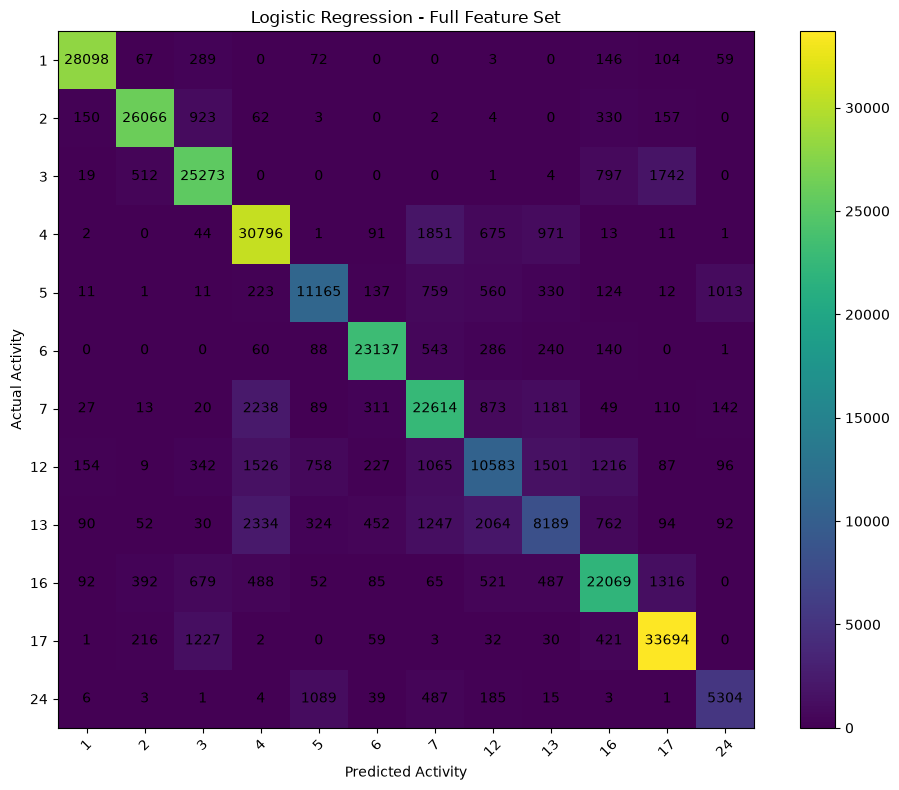

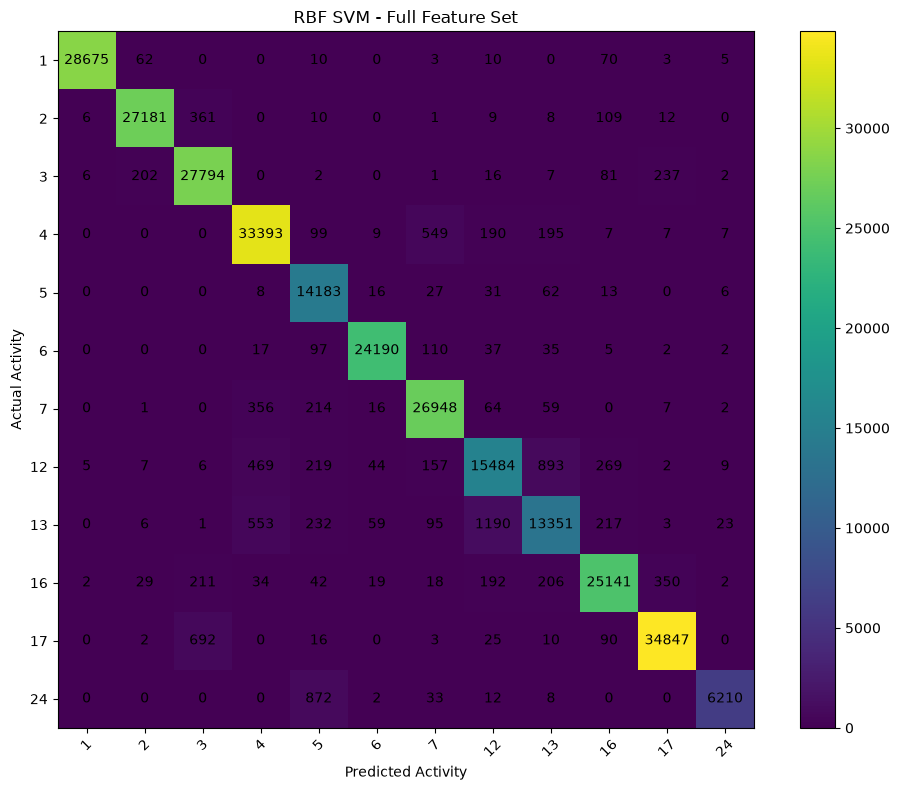

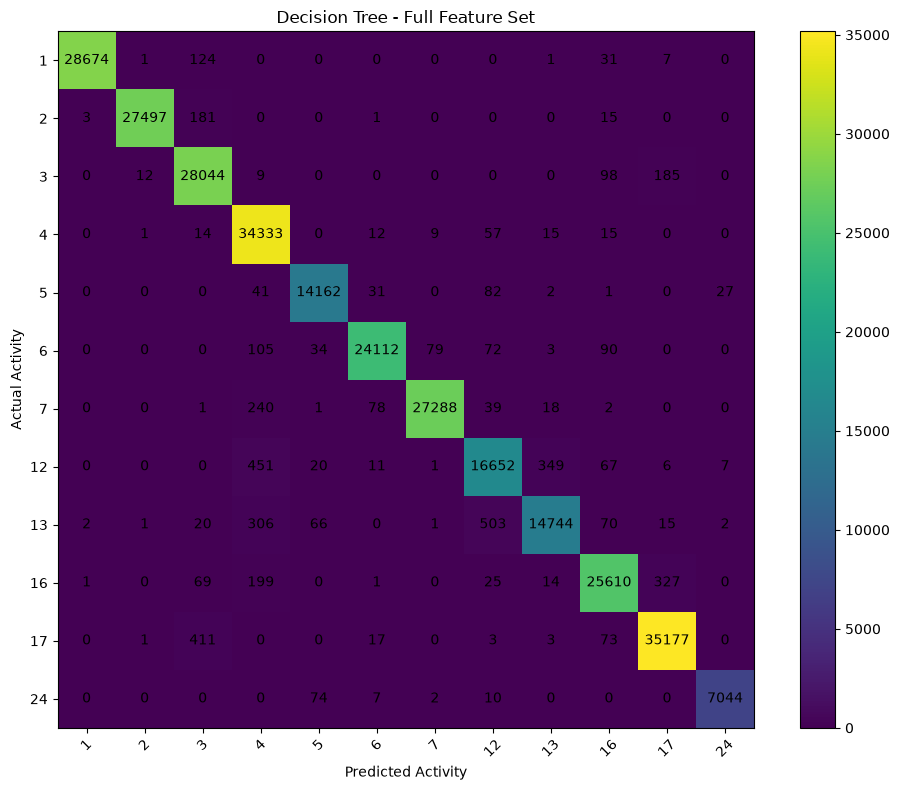

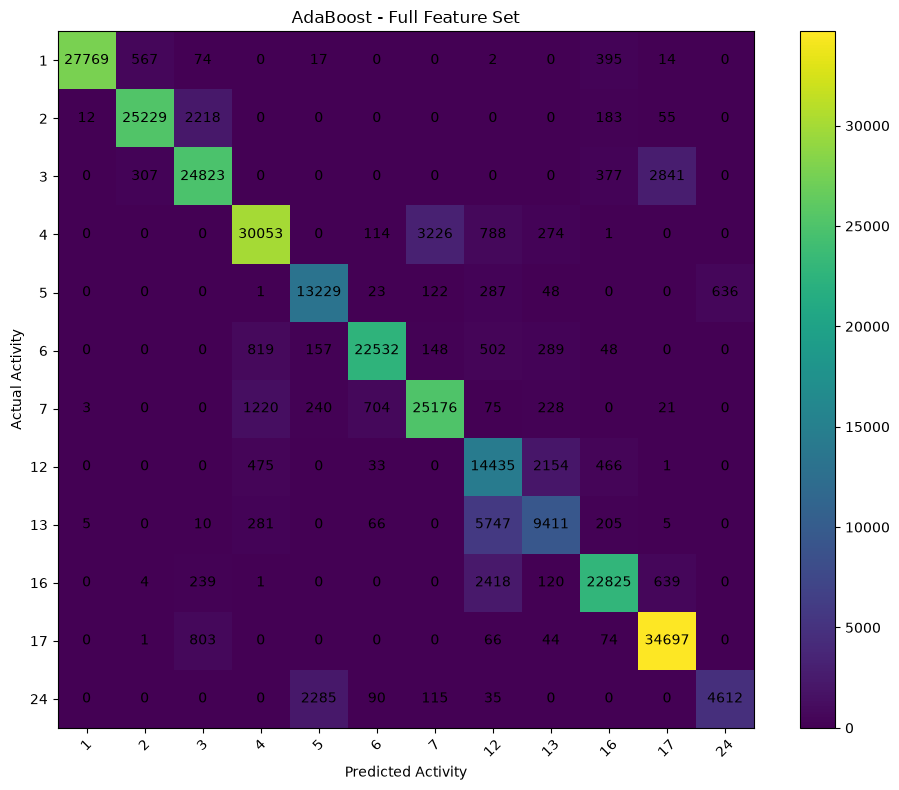

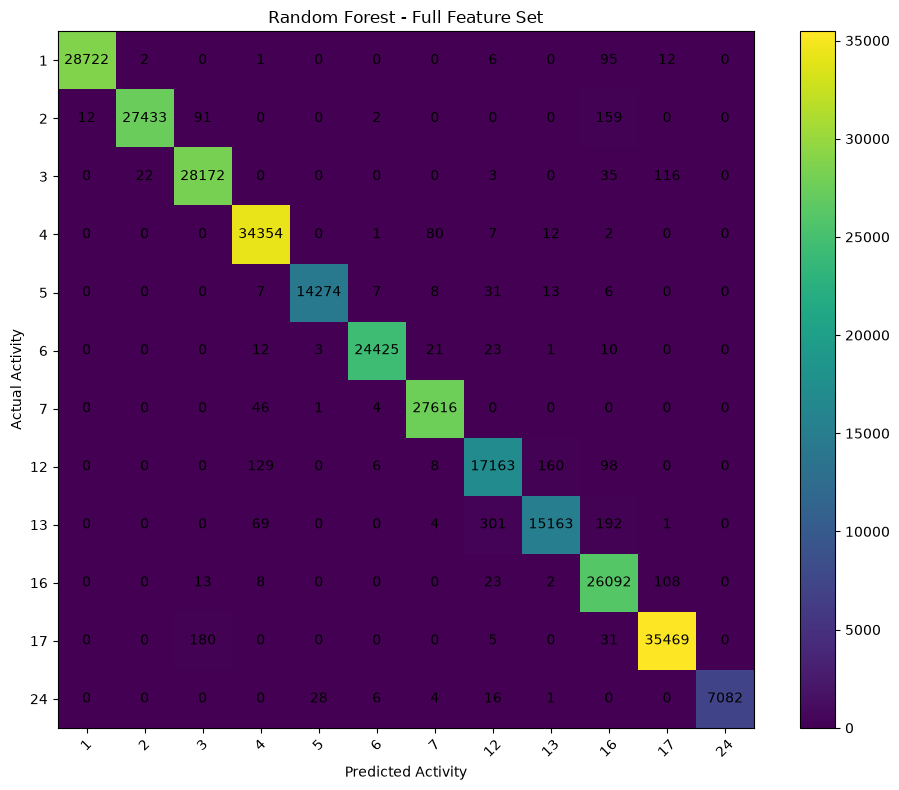

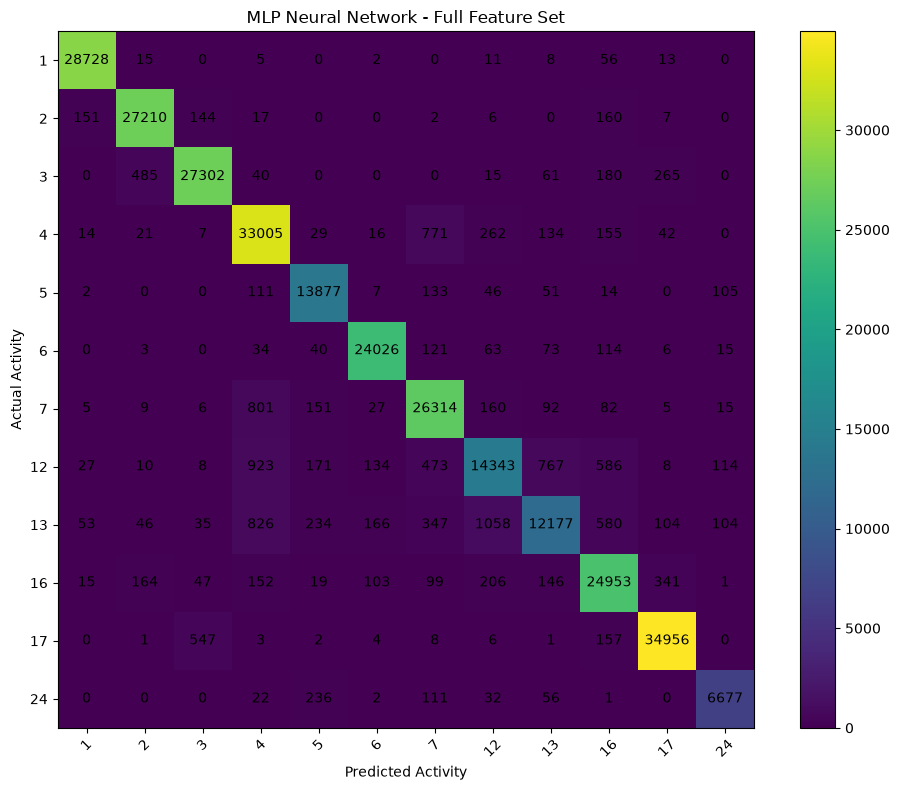

In [52]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Activity labels
activity_labels = sorted(full_y_test.unique())

full_models = {
    "Logistic Regression": full_y_pred_logreg,
    "RBF SVM": svm_full_y_pred,
    "Decision Tree": full_y_pred_tree,
    "AdaBoost": ada_full_y_pred,
    "Random Forest": rf_full_y_pred,
    "MLP Neural Network": mlp_full_y_pred
}

for model_name, predictions in full_models.items():

    cm = confusion_matrix(
        full_y_test,
        predictions,
        labels=activity_labels
    )

    plt.figure(figsize=(10, 8))

    plt.imshow(cm, interpolation="nearest")
    plt.title(f"{model_name} - Full Feature Set")
    plt.colorbar()

    plt.xticks(
        range(len(activity_labels)),
        activity_labels,
        rotation=45
    )

    plt.yticks(
        range(len(activity_labels)),
        activity_labels
    )

    plt.xlabel("Predicted Activity")
    plt.ylabel("Actual Activity")

    # Add values inside cells
    for i in range(len(activity_labels)):
        for j in range(len(activity_labels)):
            plt.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center"
            )

    plt.tight_layout()
    plt.show()

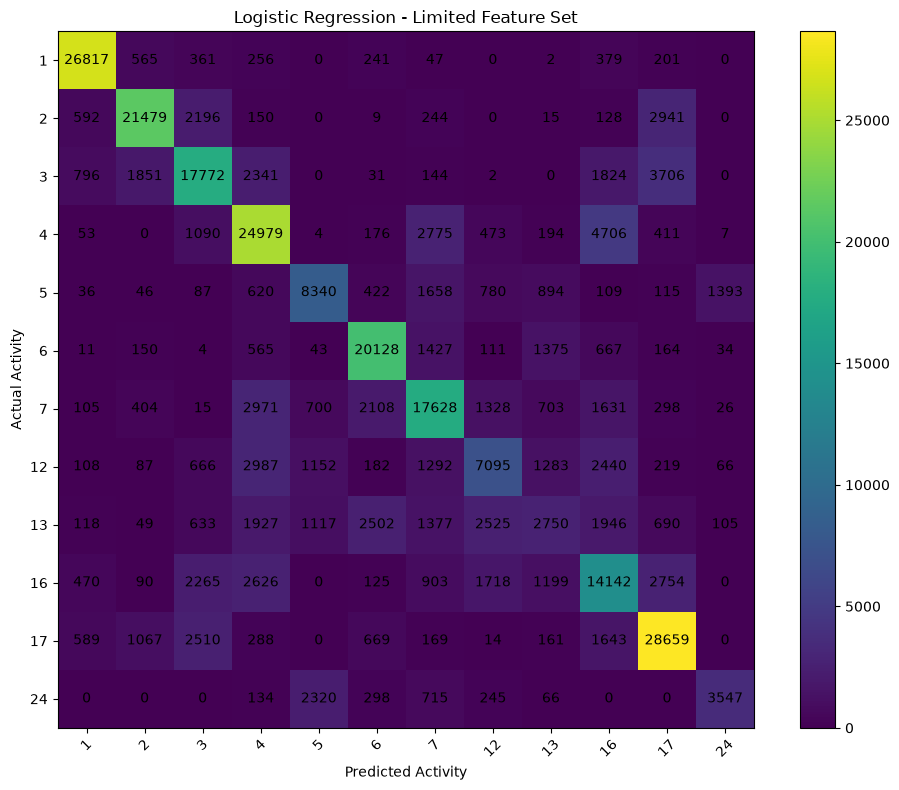

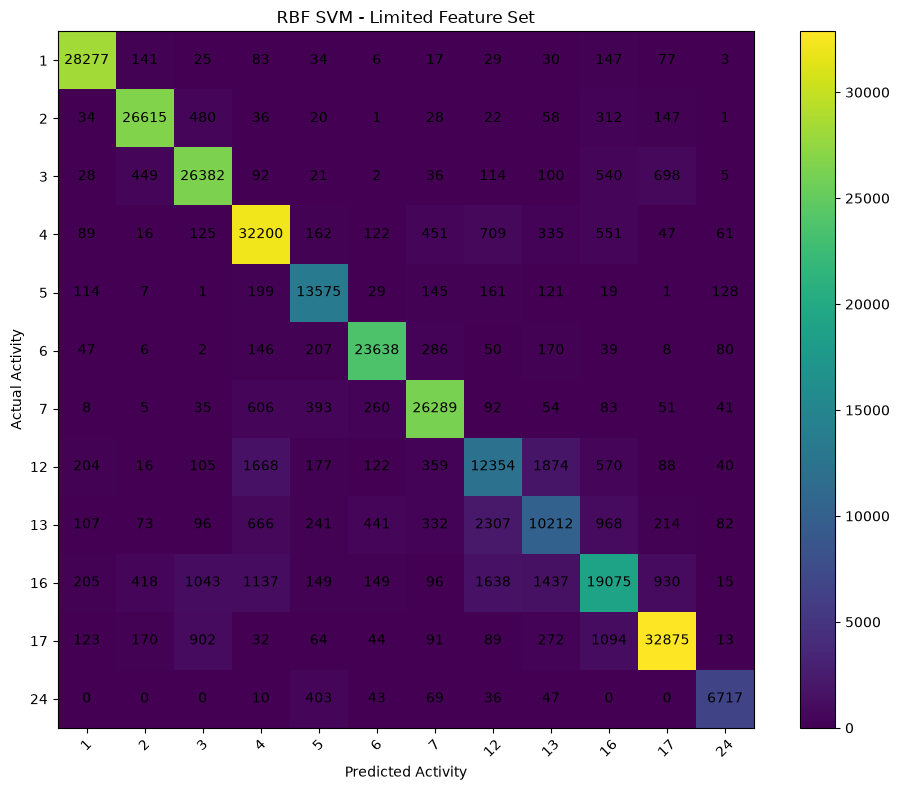

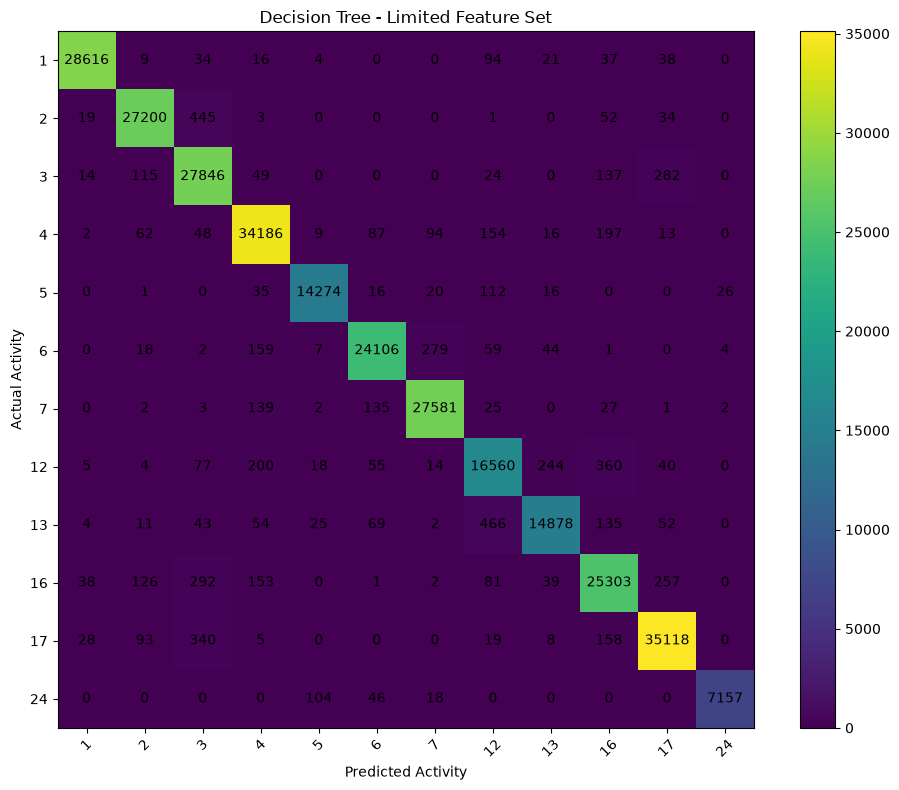

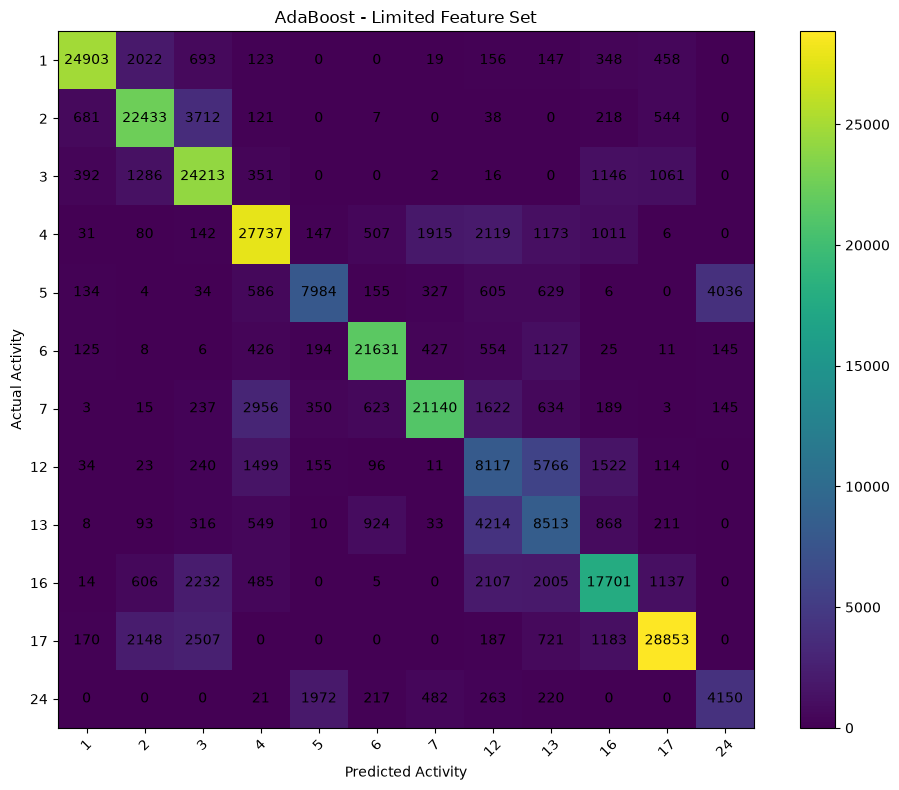

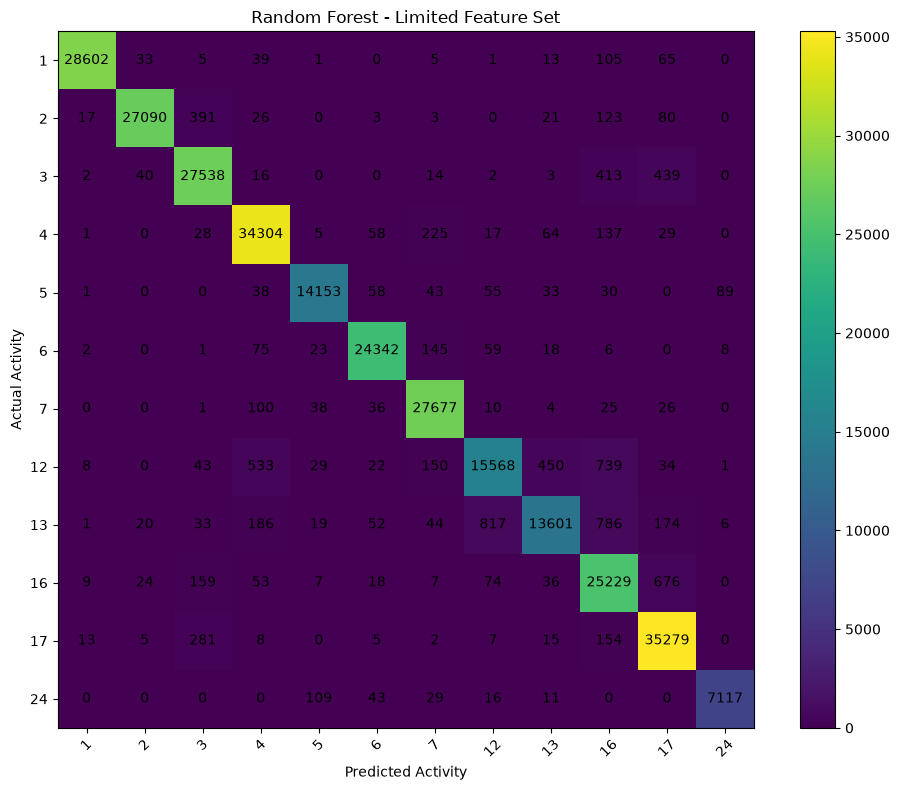

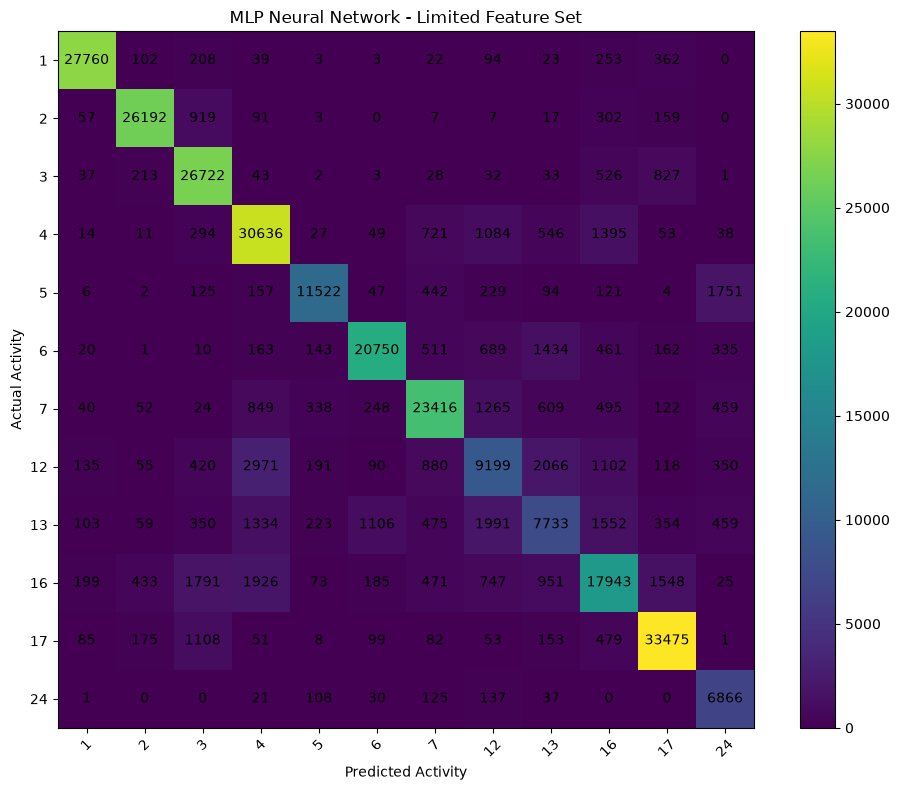

In [53]:
# Limited-feature confusion matrices

limited_models = {
    "Logistic Regression": limited_y_pred_logreg,
    "RBF SVM": svm_limited_y_pred,
    "Decision Tree": limited_y_pred_tree,
    "AdaBoost": ada_limited_y_pred,
    "Random Forest": rf_limited_y_pred,
    "MLP Neural Network": mlp_limited_y_pred
}

for model_name, predictions in limited_models.items():

    cm = confusion_matrix(
        limited_y_test,
        predictions,
        labels=activity_labels
    )

    plt.figure(figsize=(10, 8))

    plt.imshow(cm, interpolation="nearest")
    plt.title(f"{model_name} - Limited Feature Set")
    plt.colorbar()

    plt.xticks(
        range(len(activity_labels)),
        activity_labels,
        rotation=45
    )

    plt.yticks(
        range(len(activity_labels)),
        activity_labels
    )

    plt.xlabel("Predicted Activity")
    plt.ylabel("Actual Activity")

    for i in range(len(activity_labels)):
        for j in range(len(activity_labels)):
            plt.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center"
            )

    plt.tight_layout()
    plt.show()

In [54]:
# Save all confusion matrices

import os
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

CONFUSION_PATH = "../results/confusion_matrices"
os.makedirs(CONFUSION_PATH, exist_ok=True)

# Full-feature models
for model_name, predictions in full_models.items():

    cm = confusion_matrix(
        full_y_test,
        predictions,
        labels=activity_labels
    )

    plt.figure(figsize=(10, 8))
    plt.imshow(cm, interpolation="nearest")
    plt.title(f"{model_name} - Full Feature Set")
    plt.colorbar()

    plt.xticks(
        range(len(activity_labels)),
        activity_labels,
        rotation=45
    )
    plt.yticks(
        range(len(activity_labels)),
        activity_labels
    )

    plt.xlabel("Predicted Activity")
    plt.ylabel("Actual Activity")

    for i in range(len(activity_labels)):
        for j in range(len(activity_labels)):
            plt.text(
                j, i, cm[i, j],
                ha="center",
                va="center"
            )

    plt.tight_layout()

    filename = model_name.lower().replace(" ", "_") + "_full.png"

    plt.savefig(
        os.path.join(CONFUSION_PATH, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()


# Limited-feature models
for model_name, predictions in limited_models.items():

    cm = confusion_matrix(
        limited_y_test,
        predictions,
        labels=activity_labels
    )

    plt.figure(figsize=(10, 8))
    plt.imshow(cm, interpolation="nearest")
    plt.title(f"{model_name} - Limited Feature Set")
    plt.colorbar()

    plt.xticks(
        range(len(activity_labels)),
        activity_labels,
        rotation=45
    )
    plt.yticks(
        range(len(activity_labels)),
        activity_labels
    )

    plt.xlabel("Predicted Activity")
    plt.ylabel("Actual Activity")

    for i in range(len(activity_labels)):
        for j in range(len(activity_labels)):
            plt.text(
                j, i, cm[i, j],
                ha="center",
                va="center"
            )

    plt.tight_layout()

    filename = model_name.lower().replace(" ", "_") + "_limited.png"

    plt.savefig(
        os.path.join(CONFUSION_PATH, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

print("All 12 confusion matrices saved successfully.")
print("Location:", CONFUSION_PATH)

All 12 confusion matrices saved successfully.
Location: ../results/confusion_matrices


In [55]:
# Create and save final model performance results

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "RBF SVM",
        "Decision Tree",
        "AdaBoost",
        "Random Forest",
        "MLP Neural Network"
    ],

    "Full Accuracy (%)": [
        full_logreg_accuracy * 100,
        svm_full_accuracy * 100,
        full_tree_accuracy * 100,
        ada_full_accuracy * 100,
        rf_full_accuracy * 100,
        mlp_full_accuracy * 100
    ],

    "Full Precision (%)": [
        precision_score(full_y_test, full_y_pred_logreg, average="weighted") * 100,
        precision_score(full_y_test, svm_full_y_pred, average="weighted") * 100,
        precision_score(full_y_test, full_y_pred_tree, average="weighted") * 100,
        precision_score(full_y_test, ada_full_y_pred, average="weighted") * 100,
        precision_score(full_y_test, rf_full_y_pred, average="weighted") * 100,
        precision_score(full_y_test, mlp_full_y_pred, average="weighted") * 100
    ],

    "Full Recall (%)": [
        recall_score(full_y_test, full_y_pred_logreg, average="weighted") * 100,
        recall_score(full_y_test, svm_full_y_pred, average="weighted") * 100,
        recall_score(full_y_test, full_y_pred_tree, average="weighted") * 100,
        recall_score(full_y_test, ada_full_y_pred, average="weighted") * 100,
        recall_score(full_y_test, rf_full_y_pred, average="weighted") * 100,
        recall_score(full_y_test, mlp_full_y_pred, average="weighted") * 100
    ],

    "Full F1 (%)": [
        f1_score(full_y_test, full_y_pred_logreg, average="weighted") * 100,
        f1_score(full_y_test, svm_full_y_pred, average="weighted") * 100,
        f1_score(full_y_test, full_y_pred_tree, average="weighted") * 100,
        f1_score(full_y_test, ada_full_y_pred, average="weighted") * 100,
        f1_score(full_y_test, rf_full_y_pred, average="weighted") * 100,
        f1_score(full_y_test, mlp_full_y_pred, average="weighted") * 100
    ],

    "Limited Accuracy (%)": [
        limited_logreg_accuracy * 100,
        svm_limited_accuracy * 100,
        limited_tree_accuracy * 100,
        ada_limited_accuracy * 100,
        rf_limited_accuracy * 100,
        mlp_limited_accuracy * 100
    ],

    "Limited Precision (%)": [
        precision_score(limited_y_test, limited_y_pred_logreg, average="weighted") * 100,
        precision_score(limited_y_test, svm_limited_y_pred, average="weighted") * 100,
        precision_score(limited_y_test, limited_y_pred_tree, average="weighted") * 100,
        precision_score(limited_y_test, ada_limited_y_pred, average="weighted") * 100,
        precision_score(limited_y_test, rf_limited_y_pred, average="weighted") * 100,
        precision_score(limited_y_test, mlp_limited_y_pred, average="weighted") * 100
    ],

    "Limited Recall (%)": [
        recall_score(limited_y_test, limited_y_pred_logreg, average="weighted") * 100,
        recall_score(limited_y_test, svm_limited_y_pred, average="weighted") * 100,
        recall_score(limited_y_test, limited_y_pred_tree, average="weighted") * 100,
        recall_score(limited_y_test, ada_limited_y_pred, average="weighted") * 100,
        recall_score(limited_y_test, rf_limited_y_pred, average="weighted") * 100,
        recall_score(limited_y_test, mlp_limited_y_pred, average="weighted") * 100
    ],

    "Limited F1 (%)": [
        f1_score(limited_y_test, limited_y_pred_logreg, average="weighted") * 100,
        f1_score(limited_y_test, svm_limited_y_pred, average="weighted") * 100,
        f1_score(limited_y_test, limited_y_pred_tree, average="weighted") * 100,
        f1_score(limited_y_test, ada_limited_y_pred, average="weighted") * 100,
        f1_score(limited_y_test, rf_limited_y_pred, average="weighted") * 100,
        f1_score(limited_y_test, mlp_limited_y_pred, average="weighted") * 100
    ]
})

# Round values
results = results.round(2)

# Display
print("Final Model Performance:")
display(results)

# Save CSV
RESULTS_PATH = "../results"
os.makedirs(RESULTS_PATH, exist_ok=True)

results.to_csv(
    os.path.join(RESULTS_PATH, "model_performance.csv"),
    index=False
)

print("\nModel performance saved successfully.")
print("Location: ../results/model_performance.csv")

Final Model Performance:


,Model,Full Accuracy (%),Full Precision (%),Full Recall (%),Full F1 (%),Limited Accuracy (%),Limited Precision (%),Limited Recall (%),Limited F1 (%)
0,Logistic Regression,85.70,85.40,85.70,85.48,66.72,65.87,66.72,66.00
1,RBF SVM,96.44,96.28,96.25,96.24,88.82,88.97,89.11,89.00
2,Decision Tree,98.31,98.32,98.31,98.31,97.61,97.62,97.61,97.61
3,AdaBoost,88.40,89.11,88.40,88.49,75.02,76.57,75.02,75.50
4,Random Forest,99.22,99.22,99.22,99.22,96.81,96.83,96.81,96.79
5,MLP Neural Network,94.92,94.88,94.92,94.86,83.59,83.50,83.59,83.36



Model performance saved successfully.
Location: ../results/model_performance.csv


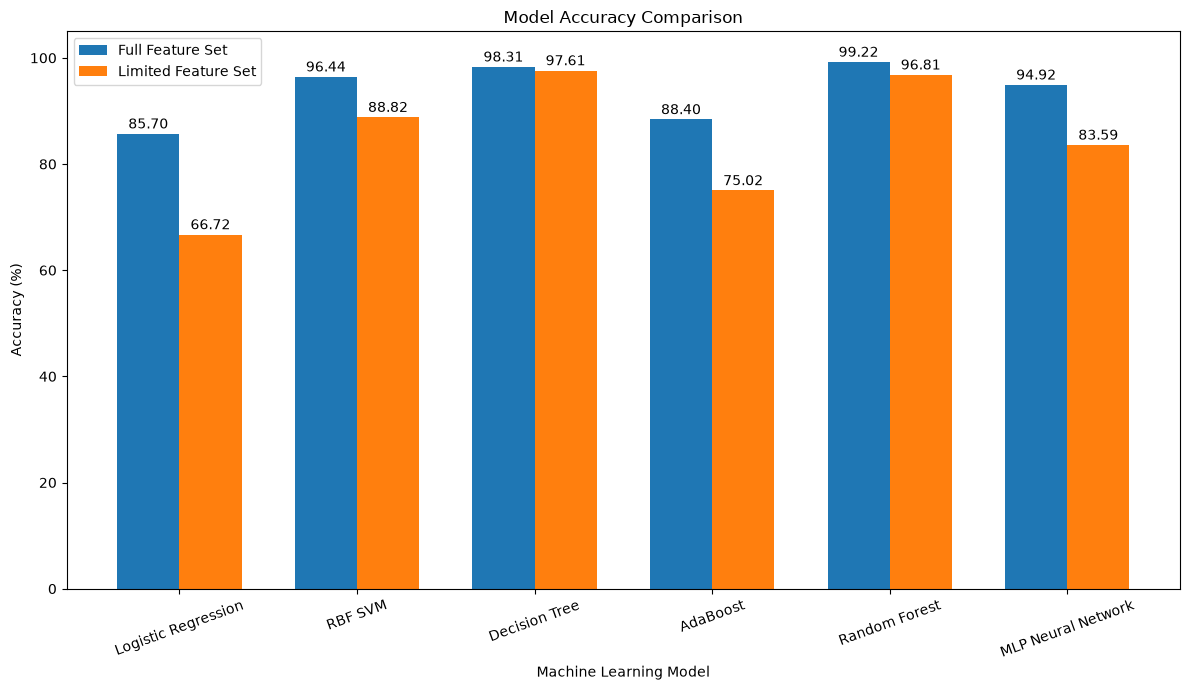

Accuracy comparison graph saved successfully.


In [56]:
# Model Accuracy Comparison

import matplotlib.pyplot as plt
import numpy as np

models = results["Model"]

full_accuracy = results["Full Accuracy (%)"]
limited_accuracy = results["Limited Accuracy (%)"]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(12, 7))

plt.bar(
    x - width/2,
    full_accuracy,
    width,
    label="Full Feature Set"
)

plt.bar(
    x + width/2,
    limited_accuracy,
    width,
    label="Limited Feature Set"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")
plt.xticks(x, models, rotation=20)
plt.ylim(0, 105)
plt.legend()

# Add values on bars
for i, value in enumerate(full_accuracy):
    plt.text(
        i - width/2,
        value + 1,
        f"{value:.2f}",
        ha="center"
    )

for i, value in enumerate(limited_accuracy):
    plt.text(
        i + width/2,
        value + 1,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "../results/model_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Accuracy comparison graph saved successfully.")

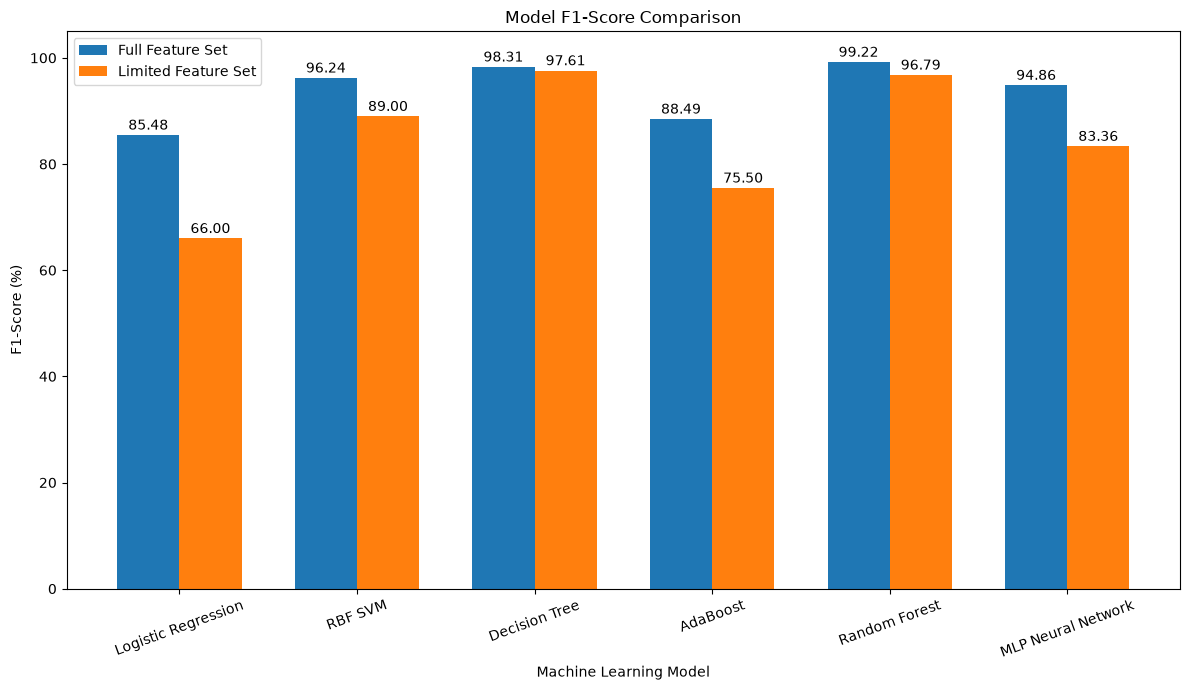

F1-score comparison graph saved successfully.


In [57]:
# Model F1-Score Comparison

full_f1 = results["Full F1 (%)"]
limited_f1 = results["Limited F1 (%)"]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(12, 7))

plt.bar(
    x - width/2,
    full_f1,
    width,
    label="Full Feature Set"
)

plt.bar(
    x + width/2,
    limited_f1,
    width,
    label="Limited Feature Set"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("F1-Score (%)")
plt.title("Model F1-Score Comparison")
plt.xticks(x, models, rotation=20)
plt.ylim(0, 105)
plt.legend()

# Add values on bars
for i, value in enumerate(full_f1):
    plt.text(
        i - width/2,
        value + 1,
        f"{value:.2f}",
        ha="center"
    )

for i, value in enumerate(limited_f1):
    plt.text(
        i + width/2,
        value + 1,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "../results/model_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("F1-score comparison graph saved successfully.")

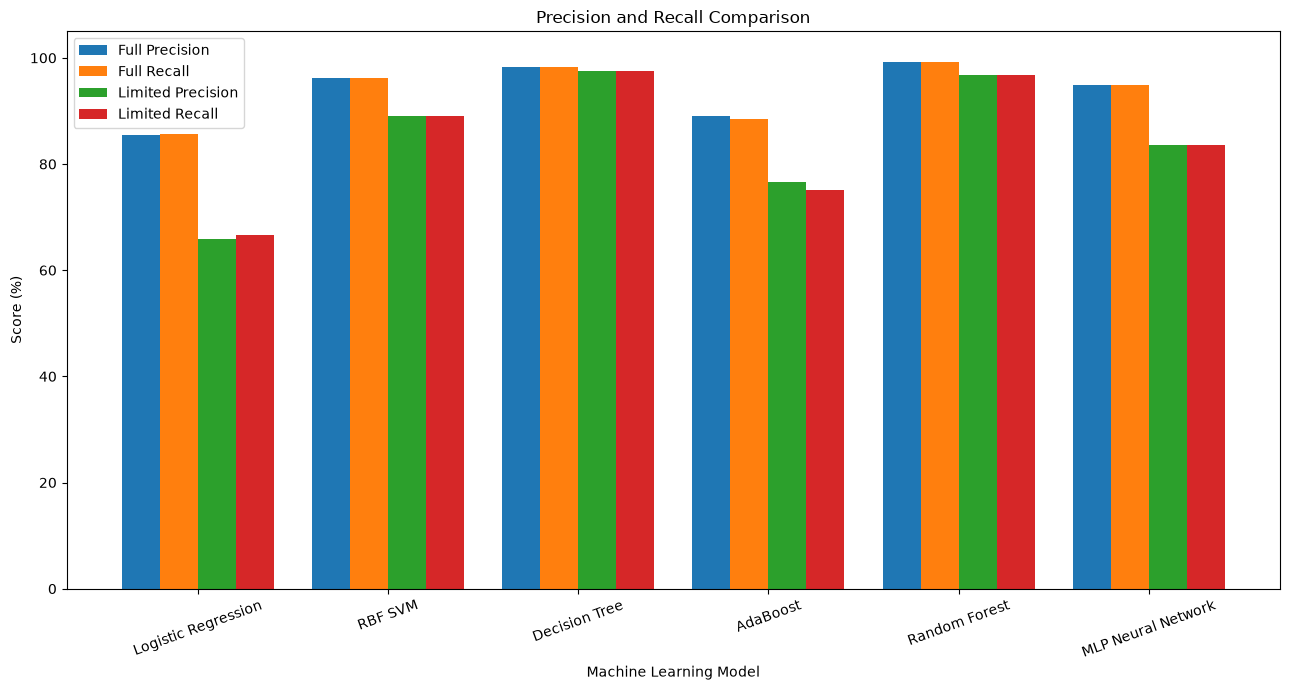

Precision and Recall comparison graph saved successfully.


In [58]:
# Precision and Recall Comparison

x = np.arange(len(models))
width = 0.20

full_precision = results["Full Precision (%)"]
full_recall = results["Full Recall (%)"]

limited_precision = results["Limited Precision (%)"]
limited_recall = results["Limited Recall (%)"]

plt.figure(figsize=(13, 7))

plt.bar(
    x - 1.5 * width,
    full_precision,
    width,
    label="Full Precision"
)

plt.bar(
    x - 0.5 * width,
    full_recall,
    width,
    label="Full Recall"
)

plt.bar(
    x + 0.5 * width,
    limited_precision,
    width,
    label="Limited Precision"
)

plt.bar(
    x + 1.5 * width,
    limited_recall,
    width,
    label="Limited Recall"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Score (%)")
plt.title("Precision and Recall Comparison")
plt.xticks(x, models, rotation=20)
plt.ylim(0, 105)
plt.legend()

plt.tight_layout()

plt.savefig(
    "../results/precision_recall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Precision and Recall comparison graph saved successfully.")

In [61]:
# Final Results Summary

print("=" * 70)
print("FINAL MODEL PERFORMANCE SUMMARY")
print("=" * 70)

display(
    results[
        [
            "Model",
            "Full Accuracy (%)",
            "Full Precision (%)",
            "Full Recall (%)",
            "Full F1 (%)",
            "Limited Accuracy (%)",
            "Limited Precision (%)",
            "Limited Recall (%)",
            "Limited F1 (%)"
        ]
    ]
)

# Identify the highest accuracy values for reference
print("\nFull-feature accuracy values:")
for _, row in results.iterrows():
    print(f"{row['Model']}: {row['Full Accuracy (%)']:.2f}%")

print("\nLimited-feature accuracy values:")
for _, row in results.iterrows():
    print(f"{row['Model']}: {row['Limited Accuracy (%)']:.2f}%")

FINAL MODEL PERFORMANCE SUMMARY


,Model,Full Accuracy (%),Full Precision (%),Full Recall (%),Full F1 (%),Limited Accuracy (%),Limited Precision (%),Limited Recall (%),Limited F1 (%)
0,Logistic Regression,85.70,85.40,85.70,85.48,66.72,65.87,66.72,66.00
1,RBF SVM,96.44,96.28,96.25,96.24,88.82,88.97,89.11,89.00
2,Decision Tree,98.31,98.32,98.31,98.31,97.61,97.62,97.61,97.61
3,AdaBoost,88.40,89.11,88.40,88.49,75.02,76.57,75.02,75.50
4,Random Forest,99.22,99.22,99.22,99.22,96.81,96.83,96.81,96.79
5,MLP Neural Network,94.92,94.88,94.92,94.86,83.59,83.50,83.59,83.36



Full-feature accuracy values:
Logistic Regression: 85.70%
RBF SVM: 96.44%
Decision Tree: 98.31%
AdaBoost: 88.40%
Random Forest: 99.22%
MLP Neural Network: 94.92%

Limited-feature accuracy values:
Logistic Regression: 66.72%
RBF SVM: 88.82%
Decision Tree: 97.61%
AdaBoost: 75.02%
Random Forest: 96.81%
MLP Neural Network: 83.59%
